In [1]:
import polars as pl

### POLARS API

In [ ]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")
df.collect_schema()

In [ ]:
df.head()

In [ ]:
df.describe()

In [ ]:
df.get_column("brand").value_counts(sort=True)
# df['brand'].value_counts(sort=True) # Same way to access column, not recommended

In [ ]:
df.select(
    pl.col("price").median().alias("median_price"),
    pl.col("brand").n_unique().alias("n_unique_brands"),
    pl.col("brand").is_not_null().sum(),
    pl.col("brand").str.len_chars().max().alias("max_brand_length"),
)

In [ ]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand"))

In [ ]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).group_by(
    "event_type", "product_id", "category_id", "category_code", "brand", "price", "median_price_over_brand"
).agg("user_id")

### Eager vs Lazy Performance

In [1]:
## NOTE: Restart kernel and clean cells at this point to free memory
import polars as pl

In [2]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")  # Eager read

In [3]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).write_parquet(
    "data/2019-Oct-10M_eager.parquet"
)

In [4]:
del df

In [5]:
df = pl.scan_parquet("data/2019-Oct-10M.parquet")

In [6]:
df.with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand")).sink_parquet(
    "data/2019-Oct-10M_eager.parquet", engine="streaming"
)

In [7]:
df_lazy_brand = pl.scan_parquet("data/2019-Oct-10M.parquet").select("brand").unique()

In [8]:
df_lazy = (
    pl.scan_parquet("data/2019-Oct.parquet")
    .join(df_lazy_brand, on="brand", how="inner")
    .with_columns(pl.col("price").median().over("brand").alias("median_price_over_brand"))
    .group_by("event_type", "product_id", "category_id", "category_code", "brand", "price", "median_price_over_brand")
    .agg(pl.col("user_id"))
    .filter(pl.col("product_id") > 100000)
)

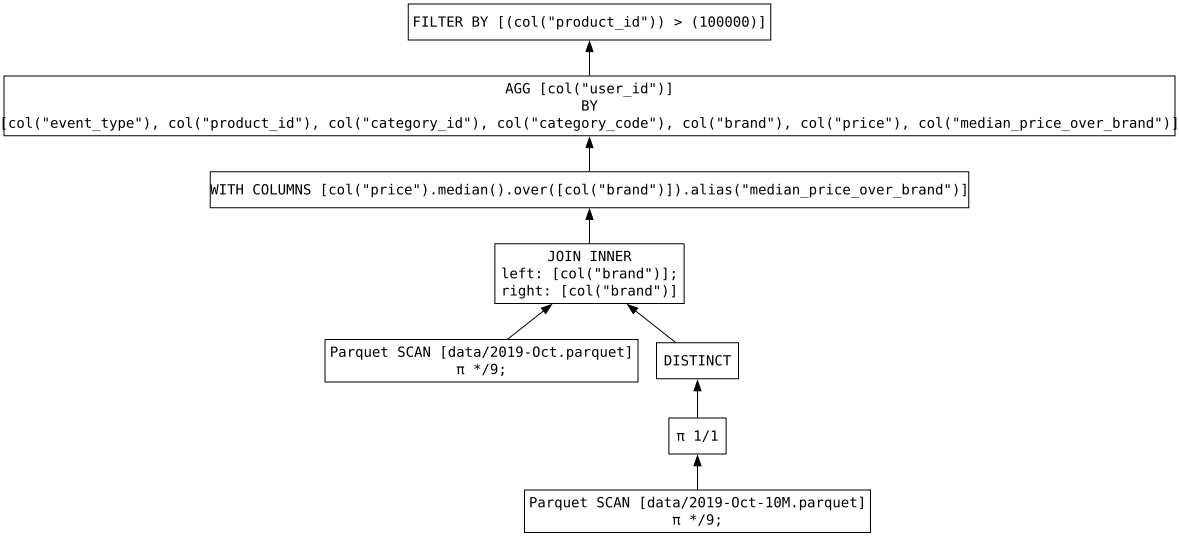

In [9]:
df_lazy.show_graph(optimized=False)

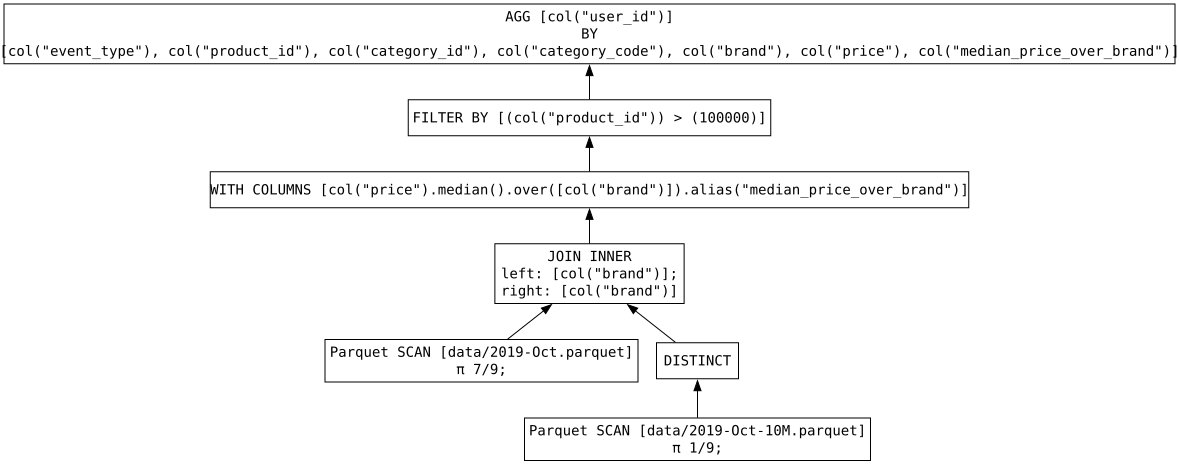

In [10]:
df_lazy.show_graph(optimized=True)

In [15]:
df_lazy.collect(engine="streaming", no_optimization=True).write_parquet("data/2019-Oct-10M_lazy_no_opt.parquet")

In [16]:
df_lazy.collect(engine="streaming").write_parquet("data/2019-Oct-10M_lazy_opt.parquet")

## Arrow interoperability

In [51]:
df = pl.read_parquet("data/2019-Oct-10M.parquet")

In [18]:
df.estimated_size("mb")

1064.689962387085

In [ ]:
df_pd = df.to_pandas(use_pyarrow_extension_array=False)
df_pd.head()

In [ ]:
df_pd_arrow = df.to_pandas(use_pyarrow_extension_array=True)
df_pd_arrow.head()

In [ ]:
import duckdb

conn = duckdb.connect("test.duckdb")

In [ ]:
conn.sql("CREATE OR REPLACE TABLE pandas_backend as SELECT * from df_pd")

In [ ]:
conn.sql("CREATE OR REPLACE  TABLE pandas_arrow as SELECT * from df_pd_arrow")

In [ ]:
conn.sql("CREATE OR REPLACE TABLE polars as SELECT * from df")

In [ ]:
conn.close()

## Open Source table formats integration

In [25]:
# Iceberg integration
from pyiceberg.schema import Schema
from pyiceberg.types import NestedField, StringType, IntegerType, FloatType, LongType
from pyiceberg.catalog import load_catalog
import os


current_dir = os.path.abspath(".")
warehouse_path = f"file://{current_dir}/warehouse"
uri = f"sqlite:///{current_dir}/pyiceberg_catalog.db"

catalog = load_catalog("default", **{"type": "sql", "uri": uri, "warehouse": warehouse_path})

schema = Schema(
    NestedField(1, "event_time", StringType(), required=False),
    NestedField(2, "event_type", StringType(), required=False),
    NestedField(3, "product_id", IntegerType(), required=False),
    NestedField(4, "category_id", LongType(), required=False),
    NestedField(5, "category_code", StringType(), required=False),
    NestedField(6, "brand", StringType(), required=False),
    NestedField(7, "price", FloatType(), required=False),
    NestedField(8, "user_id", IntegerType(), required=False),
    NestedField(9, "user_session", StringType(), required=False),
)

In [27]:
catalog.create_namespace("polars")
table = catalog.create_table("polars.2019_oct_10M", schema=schema)
df.write_iceberg(table, mode="append")

In [35]:
pl.scan_iceberg(table).head().collect()

event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
str,str,i32,i64,str,str,f32,i32,str
"""2019-10-01 00:00:00 UTC""","""view""",44600062,2103807459595387724,null,"""shiseido""",35.790001,541312140,"""72d76fde-8bb3-4e00-8c23-a032df…"
"""2019-10-01 00:00:00 UTC""","""view""",3900821,2053013552326770905,"""appliances.environment.water_h…","""aqua""",33.200001,554748717,"""9333dfbd-b87a-4708-9857-633655…"
"""2019-10-01 00:00:01 UTC""","""view""",17200506,2053013559792632471,"""furniture.living_room.sofa""",null,543.099976,519107250,"""566511c2-e2e3-422b-b695-cf8e6e…"
"""2019-10-01 00:00:01 UTC""","""view""",1307067,2053013558920217191,"""computers.notebook""","""lenovo""",251.740005,550050854,"""7c90fc70-0e80-4590-96f3-13c02c…"
"""2019-10-01 00:00:04 UTC""","""view""",1004237,2053013555631882655,"""electronics.smartphone""","""apple""",1081.97998,535871217,"""c6bd7419-2748-4c56-95b4-8cec9f…"


In [52]:
# Delta Lake integration
df.write_delta("delta_table", mode="overwrite")

In [54]:
pl.scan_delta("delta_table").head().collect()

event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
str,str,i32,i64,str,str,f32,i32,str
"""2019-10-01 00:00:00 UTC""","""view""",44600062,2103807459595387724,null,"""shiseido""",35.790001,541312140,"""72d76fde-8bb3-4e00-8c23-a032df…"
"""2019-10-01 00:00:00 UTC""","""view""",3900821,2053013552326770905,"""appliances.environment.water_h…","""aqua""",33.200001,554748717,"""9333dfbd-b87a-4708-9857-633655…"
"""2019-10-01 00:00:01 UTC""","""view""",17200506,2053013559792632471,"""furniture.living_room.sofa""",null,543.099976,519107250,"""566511c2-e2e3-422b-b695-cf8e6e…"
"""2019-10-01 00:00:01 UTC""","""view""",1307067,2053013558920217191,"""computers.notebook""","""lenovo""",251.740005,550050854,"""7c90fc70-0e80-4590-96f3-13c02c…"
"""2019-10-01 00:00:04 UTC""","""view""",1004237,2053013555631882655,"""electronics.smartphone""","""apple""",1081.97998,535871217,"""c6bd7419-2748-4c56-95b4-8cec9f…"
